# Optimum Progress and Calibration

For weeks 2 and 3, this notebook compares the previous best-so-far, the expected best-so-far saved in `predictions.json`, and the observed best-so-far. It also checks how well the expected outputs match the observed outputs.

In [1]:
%matplotlib inline
from pathlib import Path
import json

from IPython.display import display
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from sklearn.gaussian_process.kernels import ConstantKernel, Matern, WhiteKernel, RBF

from bayesian_bbo import CONFIG, FUNCTION_SPECS, load_observations
from bayesian_bbo.optimisation import BayesianOptimizer, OptimisationConfig
from bayesian_bbo.visualisation import (
    plot_calibration,
    plot_gp_2d,
    plot_gp_slices,
    plot_optimum_progress,
)

WEEKS = (2, 3)
FUNCTION_IDS = tuple(FUNCTION_SPECS)

data_candidates = [Path("../../data"), Path("data"), Path("../data")]
matches = [path.resolve() for path in data_candidates if (path / "function_1").is_dir()]
if not matches:
    raise FileNotFoundError("Could not find the data directory from the notebook working directory.")
data_root: Path = matches[0]
print(f"Data root: {data_root}")

Data root: /home/pabloncho/repositories/bayesian-bbo/data


## 1. Load Best-so-far Values and Residuals

In [2]:
previous_best = np.empty((len(FUNCTION_IDS), len(WEEKS)))
expected_best = np.empty_like(previous_best)
observed_best = np.empty_like(previous_best)
residuals = {function_id: [] for function_id in FUNCTION_IDS}

for week_index, week in enumerate(WEEKS):
    predictions_path = data_root / "weekly_updates" / f"week_{week}" / "predictions.json"
    predictions = json.loads(predictions_path.read_text(encoding="utf-8"))
    for function_index, function_id in enumerate(FUNCTION_IDS):
        before = load_observations(data_root, function_id, up_to_week=week - 1)
        through = load_observations(data_root, function_id, up_to_week=week)
        this_week = through.weeks == week
        mean = through.expected_outputs[this_week]
        std = through.stds[this_week]
        if len(mean) != 1 or not np.isclose(mean[0], predictions["expected_outputs"][function_index]):
            raise ValueError(f"Stored expected output differs from predictions.json: function {function_id}, week {week}")
        if not np.all(std > 0):
            raise ValueError(f"Standard deviation must be positive: function {function_id}, week {week}")

        previous_best[function_index, week_index] = before.best_output
        observed_best[function_index, week_index] = through.best_output
        expected_best[function_index, week_index] = predictions["expected_best_outputs"][function_index]
        residuals[function_id].extend(((through.outputs[this_week] - mean) / std).tolist())

pd.DataFrame(
    {
        f"Week {week} {label}": values[:, week_index]
        for week_index, week in enumerate(WEEKS)
        for label, values in (("previous", previous_best), ("expected", expected_best), ("observed", observed_best))
    },
    index=[f"Function {function_id}" for function_id in FUNCTION_IDS],
).round(4)

,Week 2 previous,Week 2 expected,Week 2 observed,Week 3 previous,Week 3 expected,Week 3 observed
Function 1,0.0000,0.0012,0.0000,0.0000,0.0004,0.0000
Function 2,0.6112,0.6443,0.6112,0.6112,0.6321,0.6112
Function 3,-0.0348,-0.0197,-0.0059,-0.0059,0.0233,-0.0059
Function 4,-4.0255,-3.4646,-3.3364,-3.3364,-2.6195,-1.2696
Function 5,1088.8596,1090.5900,1397.5451,1397.5451,1720.3868,1588.5985
Function 6,-0.7143,-0.6695,-0.7143,-0.7143,-0.4368,-0.4670
Function 7,1.3650,1.3650,1.3650,1.3650,1.3710,2.3677
Function 8,9.5985,9.6188,9.5985,9.5985,9.8809,9.8811


## 2. Optimum Progress

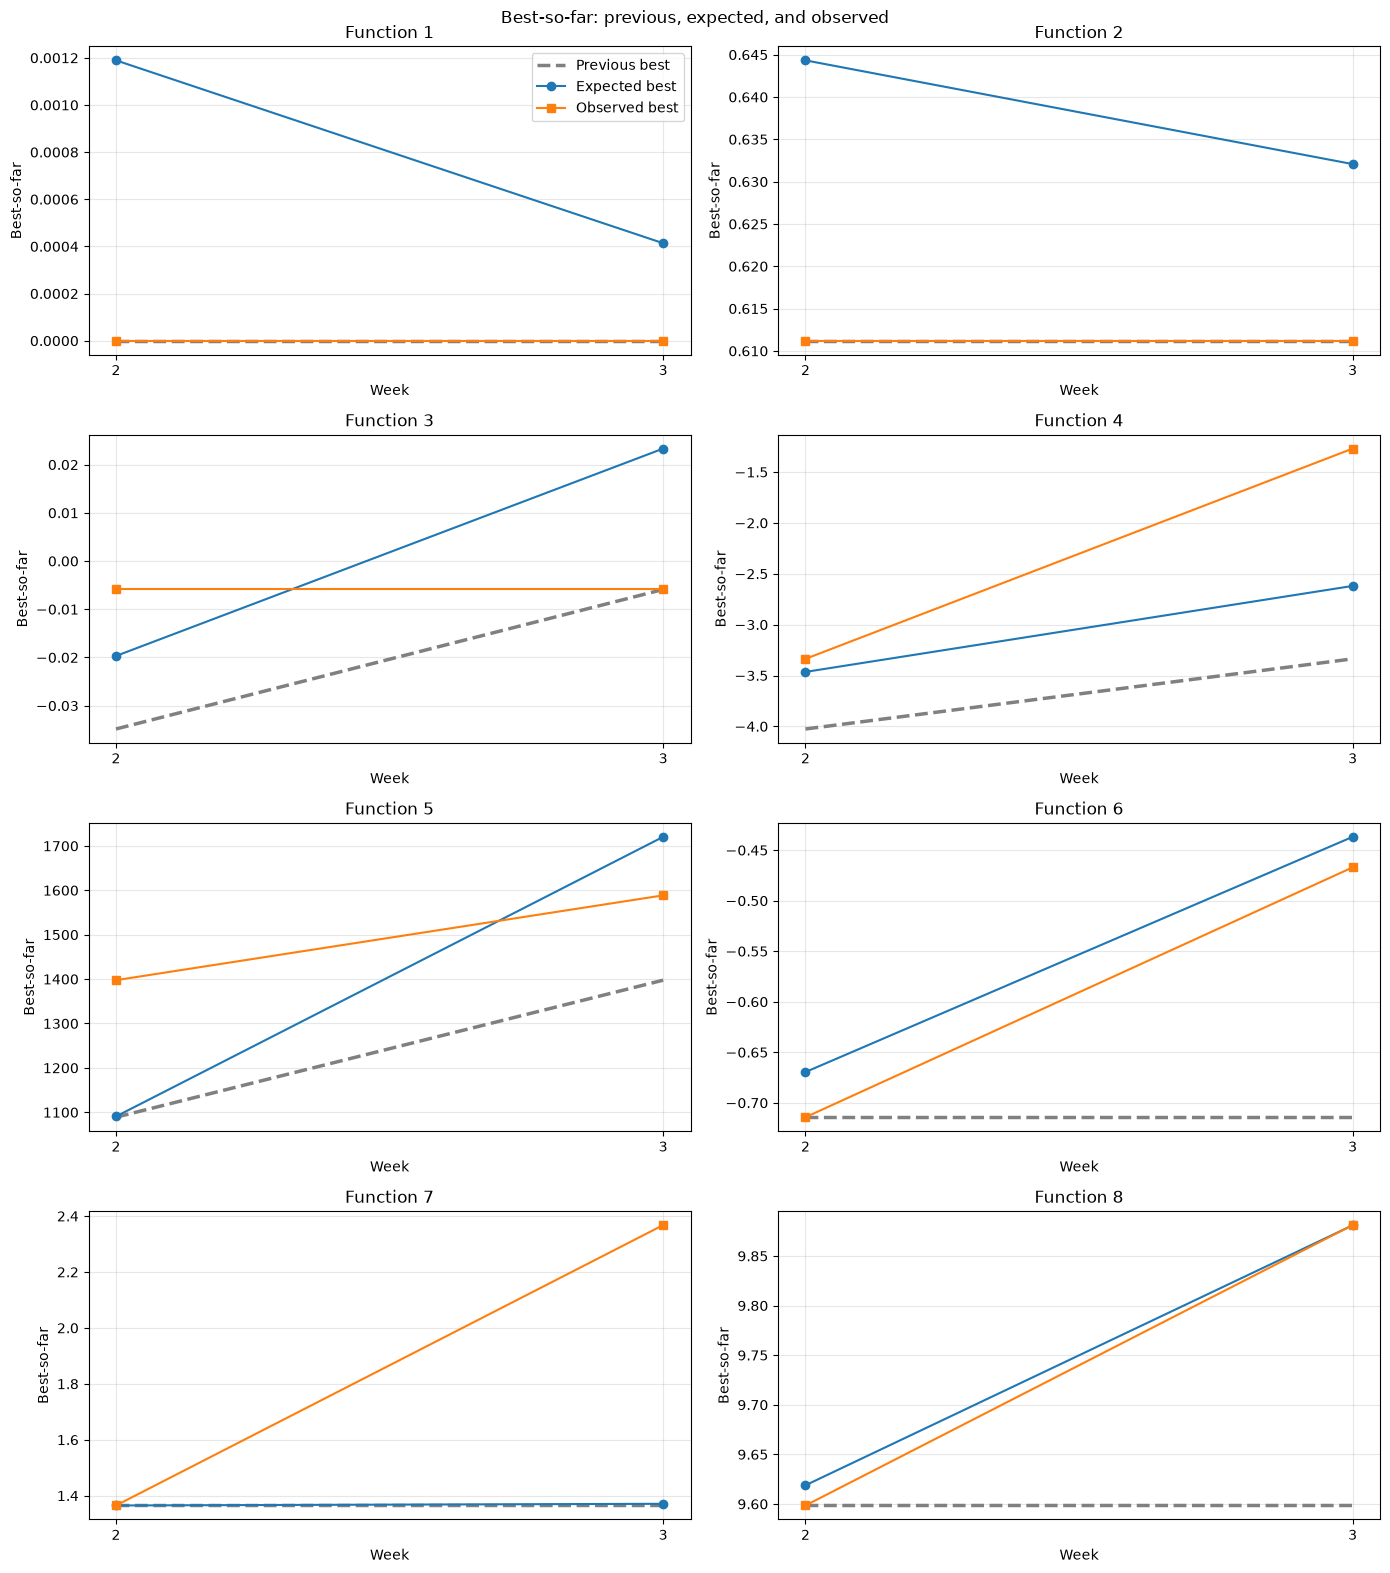

In [3]:
%matplotlib inline
optimum_figure, optimum_axes = plot_optimum_progress(
    WEEKS, FUNCTION_IDS, previous_best, expected_best, observed_best
)
display(optimum_figure)
plt.close(optimum_figure)

## 3. Calibration of Expected Outputs

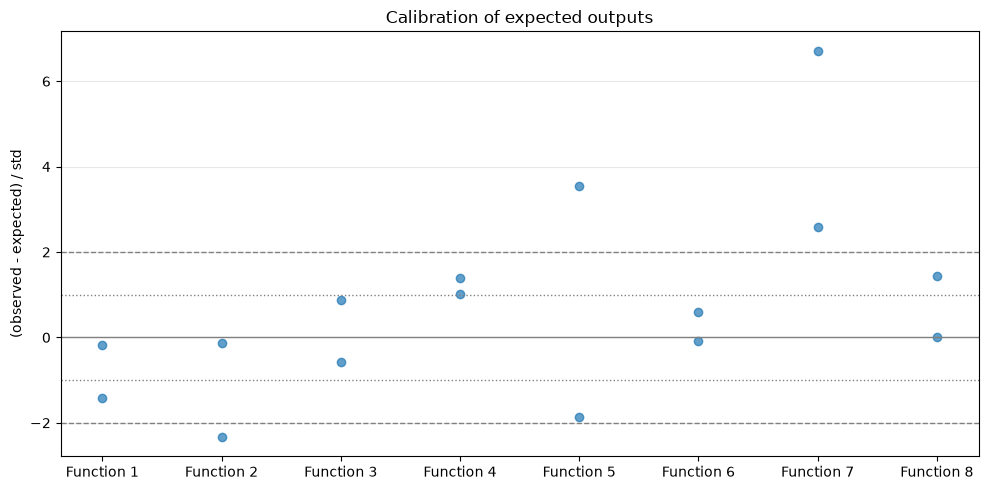

In [4]:
%matplotlib inline
calibration_figure, calibration_ax = plot_calibration(residuals)
display(calibration_figure)
plt.close(calibration_figure)

## Notes

- The expected best-so-far is never below the previous best, because $\mathbb{E}[\max(f(x), f^*)] \ge f^*$.
- Each week has one observation per function, so each observed value is a single sample.
- The residuals are $z = (y - \mu)/\sigma$ for each week's suggested point. With only 16 residuals, values beyond $\pm 2$ are a rough warning, not a conclusion.

In [5]:
LENGTH_CAPS = CONFIG["length_caps"]
XI_VALUES = {
    1: 9.96663063489224e-05, 2: 0.023266943506776105,
    3: 0.008391546020766163, 4: 0.7701378406861035,
    5: 45.21617607937864, 6: 0.10005542729396313,
    7: 0.0988599706959349, 8: 0.20097788613469525,
}


def make_matern_32_kernel(dimension, length_cap):
    return (
        ConstantKernel(1.0, (1e-3, 1e3))
        * Matern(np.ones(dimension), length_scale_bounds=(1e-3, length_cap), nu=1.5)
        # *RBF(length_scale=np.ones(dimension), length_scale_bounds=(1e-3, length_cap))
        + WhiteKernel(1e-5, (1e-8, 1e1))
    )

    
week_dir = data_root / "weekly_updates" / f"week_{WEEKS[-1]}"
with (week_dir / "inputs.json").open() as stream:
    stored_inputs = json.load(stream)
with (week_dir / "predictions.json").open() as stream:
    stored_predictions = json.load(stream)

if len(stored_inputs) != len(FUNCTION_IDS):
    raise ValueError("Stored inputs must contain one point per function")
for key in ("expected_outputs", "stds", "acquisition_scores", "acquisition_settings"):
    if len(stored_predictions[key]) != len(FUNCTION_IDS):
        raise ValueError(f"Stored {key} must contain one entry per function")
if any(settings["name"] != "ei" for settings in stored_predictions["acquisition_settings"]):
    raise ValueError("These EI diagnostics require saved EI scores, not UCB scores")
if not np.all(np.isfinite(stored_predictions["acquisition_scores"])) or np.any(
    np.asarray(stored_predictions["acquisition_scores"]) < 0
):
    raise ValueError("Stored EI scores must be finite and nonnegative")
pd.DataFrame({
    "function_id": FUNCTION_IDS,
    "suggested_point": stored_inputs,
    "expected_value": stored_predictions["expected_outputs"],
    "std": stored_predictions["stds"],
    "expected_ei": stored_predictions["acquisition_scores"],
})

,function_id,suggested_point,expected_value,std,expected_ei
0,1,"[0.7021, 0.165487]",0.000141,0.000848,0.000358
1,2,"[0.689383, 0.099113]",0.608134,0.056081,0.012136
2,3,"[0.292059, 0.194387, 0.490197]",0.000256,0.065249,0.024866
3,4,"[0.358431, 0.52023, 0.428009, 0.407961]",-2.893219,1.157735,0.331439
4,5,"[0.421782, 0.48008, 0.974874, 0.997647]",1720.386794,71.126598,287.082427
5,6,"[0.50831, 0.364919, 0.501744, 0.958429, 0.07661]",-0.447812,0.214298,0.236821
6,7,"[0.038283, 0.116645, 0.103052, 0.287496, 0.333...",1.084241,0.191096,0.004001
7,8,"[0.07949, 0.193771, 0.285174, 0.184983, 0.7237...",9.880347,0.126572,0.189124


/home/pabloncho/repositories/bayesian-bbo/.venv/lib/python3.14/site-packages/sklearn/gaussian_process/kernels.py:455: ConvergenceWarning: The optimal value found for dimension 0 of parameter k1__k2__length_scale is close to the specified upper bound 31.622776601683793. Increasing the bound and calling fit again may find a better value.
  warnings.warn(
/home/pabloncho/repositories/bayesian-bbo/.venv/lib/python3.14/site-packages/sklearn/gaussian_process/kernels.py:445: ConvergenceWarning: The optimal value found for dimension 0 of parameter k2__noise_level is close to the specified lower bound 1e-08. Decreasing the bound and calling fit again may find a better value.
  warnings.warn(


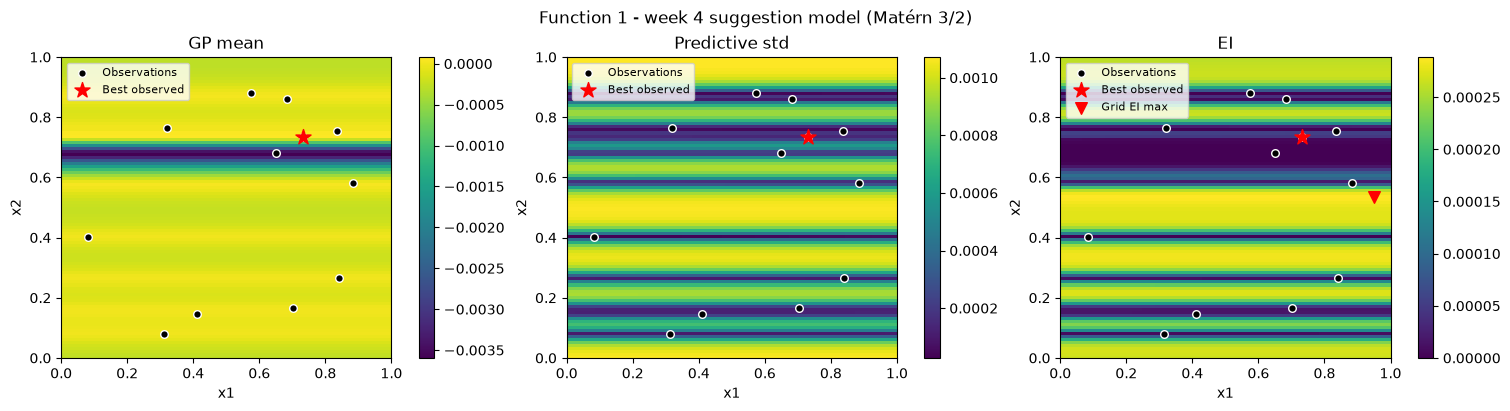

Function 1 - week 4 suggestion model kernel: 1.08**2 * Matern(length_scale=[31.6, 0.0377], nu=1.5) + WhiteKernel(noise_level=1e-08)



/home/pabloncho/repositories/bayesian-bbo/.venv/lib/python3.14/site-packages/sklearn/gaussian_process/kernels.py:455: ConvergenceWarning: The optimal value found for dimension 1 of parameter k1__k2__length_scale is close to the specified upper bound 31.622776601683793. Increasing the bound and calling fit again may find a better value.
  warnings.warn(


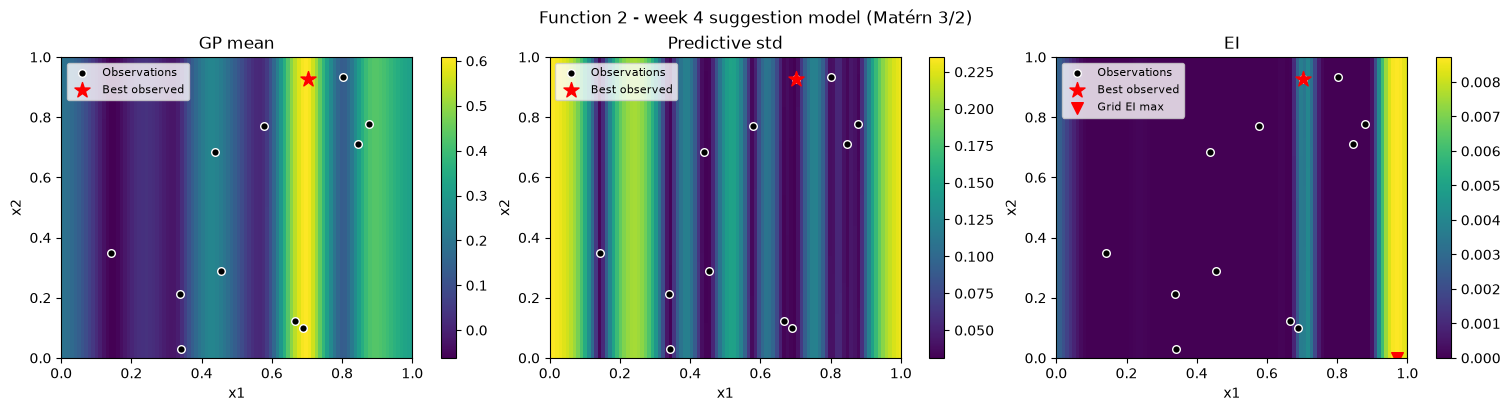

Function 2 - week 4 suggestion model kernel: 1.02**2 * Matern(length_scale=[0.0776, 31.6], nu=1.5) + WhiteKernel(noise_level=0.0107)



/home/pabloncho/repositories/bayesian-bbo/.venv/lib/python3.14/site-packages/sklearn/gaussian_process/kernels.py:455: ConvergenceWarning: The optimal value found for dimension 0 of parameter k1__k2__length_scale is close to the specified upper bound 31.622776601683793. Increasing the bound and calling fit again may find a better value.
  warnings.warn(
/home/pabloncho/repositories/bayesian-bbo/.venv/lib/python3.14/site-packages/sklearn/gaussian_process/kernels.py:455: ConvergenceWarning: The optimal value found for dimension 1 of parameter k1__k2__length_scale is close to the specified upper bound 31.622776601683793. Increasing the bound and calling fit again may find a better value.
  warnings.warn(


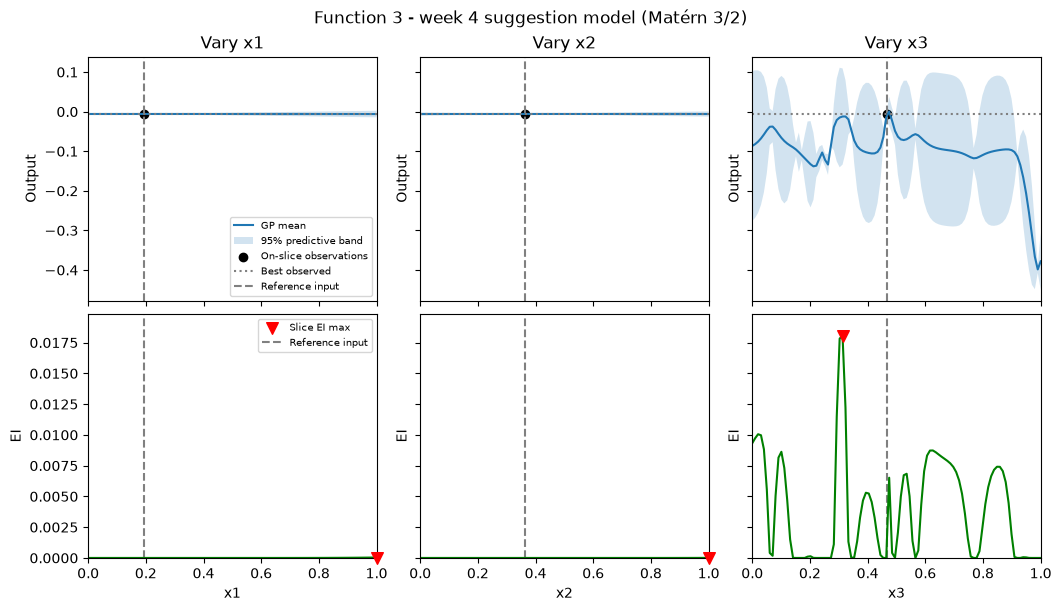

Function 3 - week 4 suggestion model kernel: 1.17**2 * Matern(length_scale=[31.6, 31.6, 0.036], nu=1.5) + WhiteKernel(noise_level=1e-06)



/home/pabloncho/repositories/bayesian-bbo/.venv/lib/python3.14/site-packages/sklearn/gaussian_process/kernels.py:445: ConvergenceWarning: The optimal value found for dimension 0 of parameter k2__noise_level is close to the specified lower bound 1e-08. Decreasing the bound and calling fit again may find a better value.
  warnings.warn(


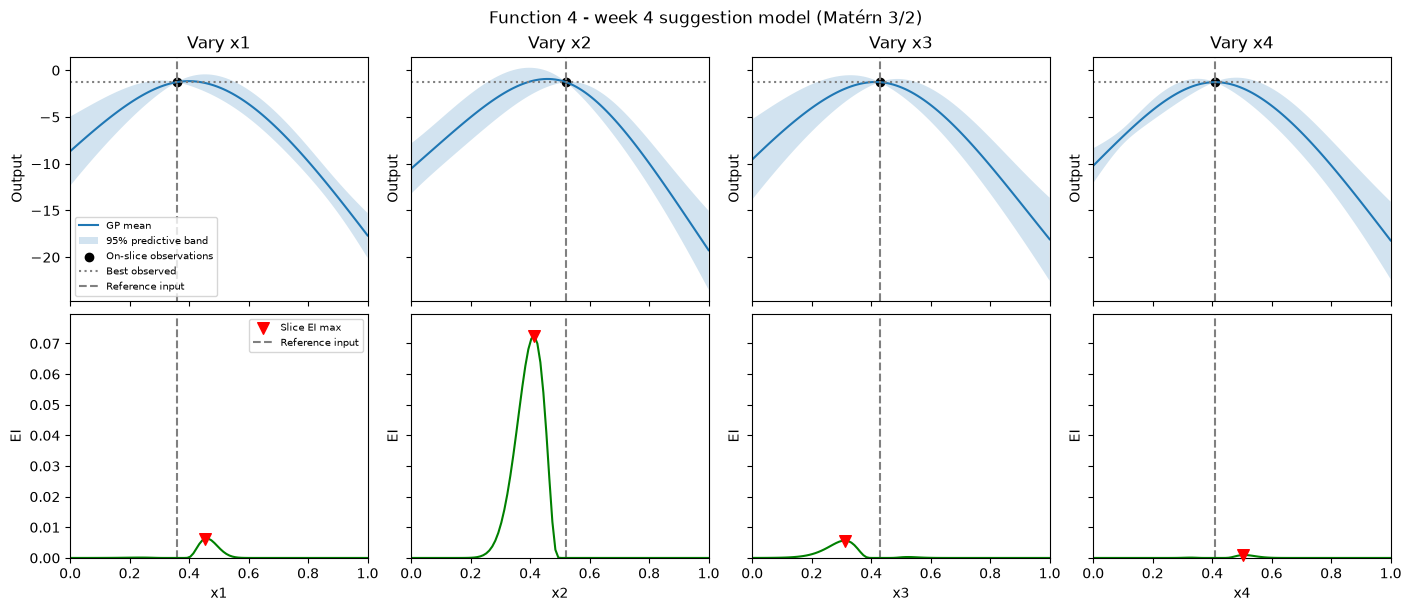

Function 4 - week 4 suggestion model kernel: 5.75**2 * Matern(length_scale=[3.99, 3.5, 3.83, 3.74], nu=1.5) + WhiteKernel(noise_level=1e-08)



/home/pabloncho/repositories/bayesian-bbo/.venv/lib/python3.14/site-packages/sklearn/gaussian_process/kernels.py:455: ConvergenceWarning: The optimal value found for dimension 0 of parameter k1__k2__length_scale is close to the specified upper bound 100.0. Increasing the bound and calling fit again may find a better value.
  warnings.warn(
/home/pabloncho/repositories/bayesian-bbo/.venv/lib/python3.14/site-packages/sklearn/gaussian_process/kernels.py:445: ConvergenceWarning: The optimal value found for dimension 0 of parameter k2__noise_level is close to the specified lower bound 1e-08. Decreasing the bound and calling fit again may find a better value.
  warnings.warn(


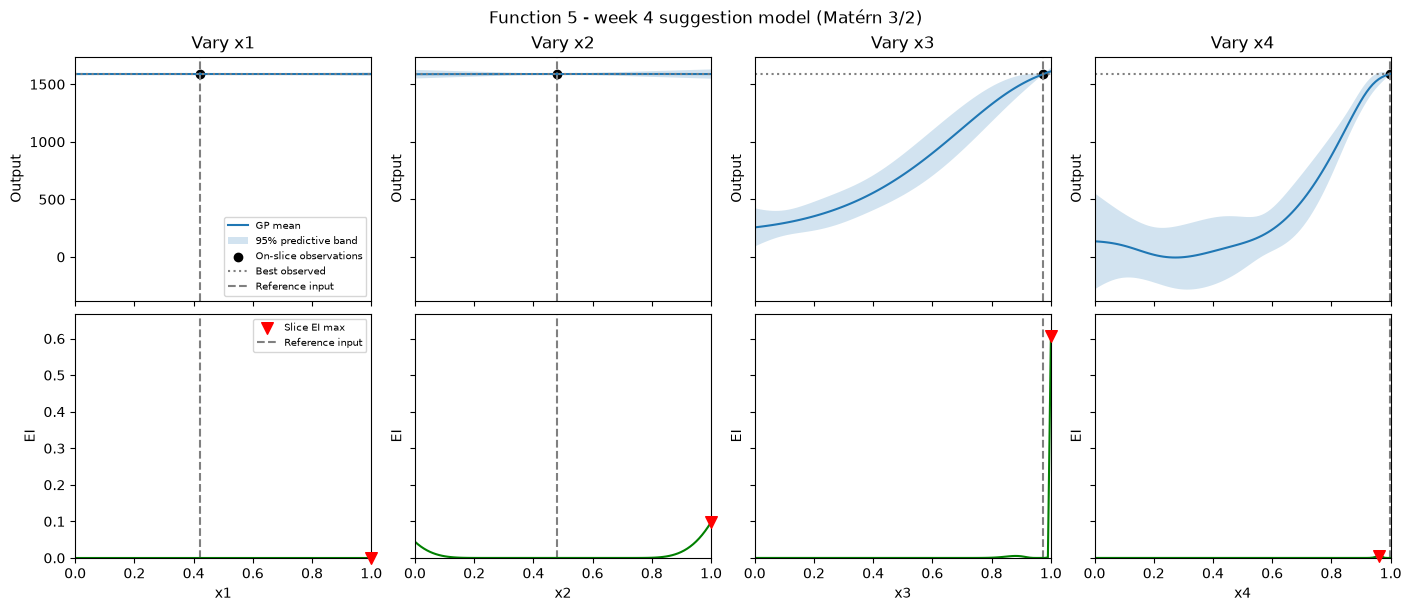

Function 5 - week 4 suggestion model kernel: 1.6**2 * Matern(length_scale=[100, 30.3, 1.37, 0.617], nu=1.5) + WhiteKernel(noise_level=1e-08)



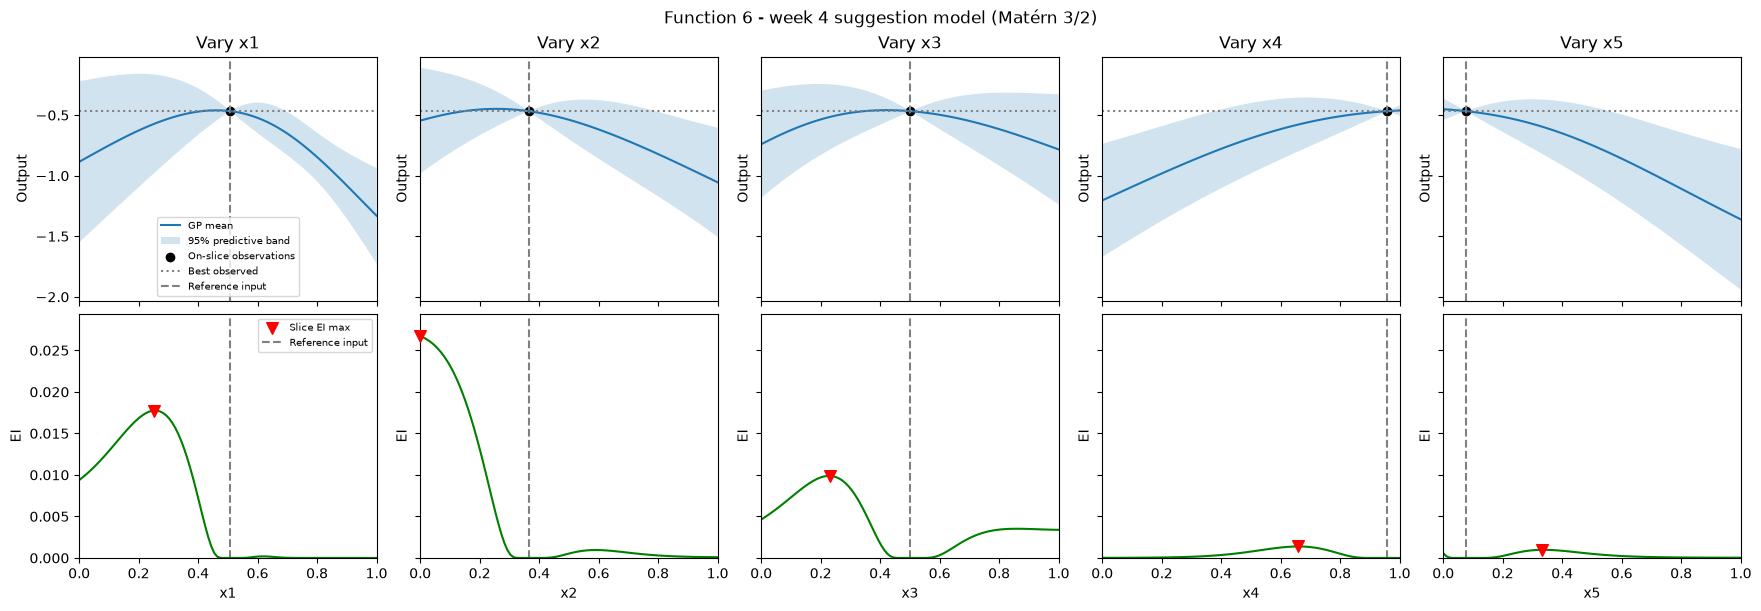

Function 6 - week 4 suggestion model kernel: 2.17**2 * Matern(length_scale=[1.22, 1.67, 1.75, 2.63, 2.19], nu=1.5) + WhiteKernel(noise_level=1e-05)



/home/pabloncho/repositories/bayesian-bbo/.venv/lib/python3.14/site-packages/sklearn/gaussian_process/kernels.py:455: ConvergenceWarning: The optimal value found for dimension 2 of parameter k1__k2__length_scale is close to the specified upper bound 31.622776601683793. Increasing the bound and calling fit again may find a better value.
  warnings.warn(


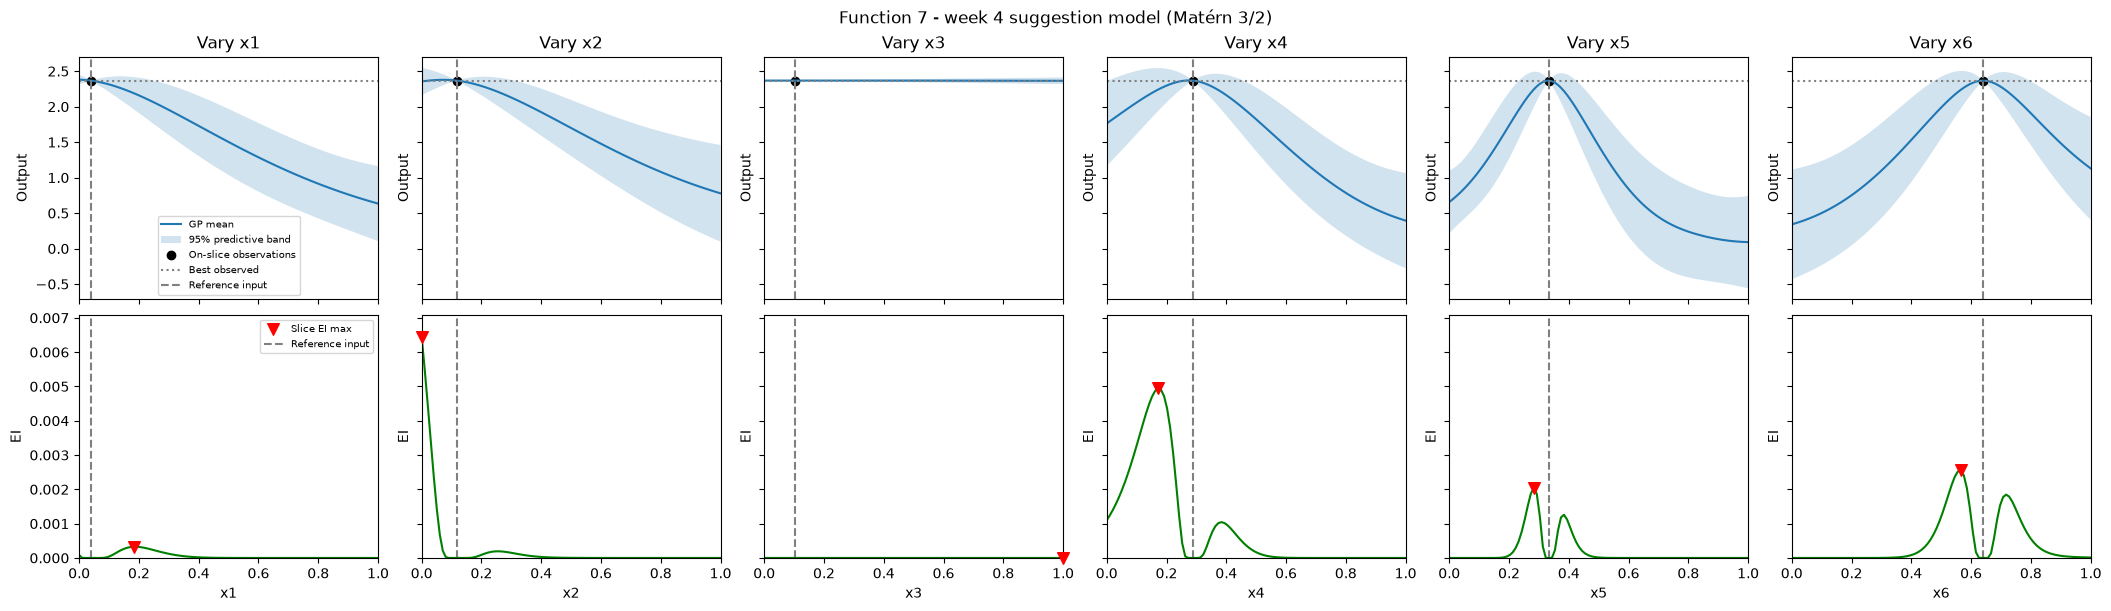

Function 7 - week 4 suggestion model kernel: 1.01**2 * Matern(length_scale=[0.868, 0.869, 31.6, 0.529, 0.265, 0.397], nu=1.5) + WhiteKernel(noise_level=9.98e-06)



/home/pabloncho/repositories/bayesian-bbo/.venv/lib/python3.14/site-packages/sklearn/gaussian_process/kernels.py:455: ConvergenceWarning: The optimal value found for dimension 7 of parameter k1__k2__length_scale is close to the specified upper bound 100.0. Increasing the bound and calling fit again may find a better value.
  warnings.warn(
/home/pabloncho/repositories/bayesian-bbo/.venv/lib/python3.14/site-packages/sklearn/gaussian_process/kernels.py:445: ConvergenceWarning: The optimal value found for dimension 0 of parameter k2__noise_level is close to the specified lower bound 1e-08. Decreasing the bound and calling fit again may find a better value.
  warnings.warn(


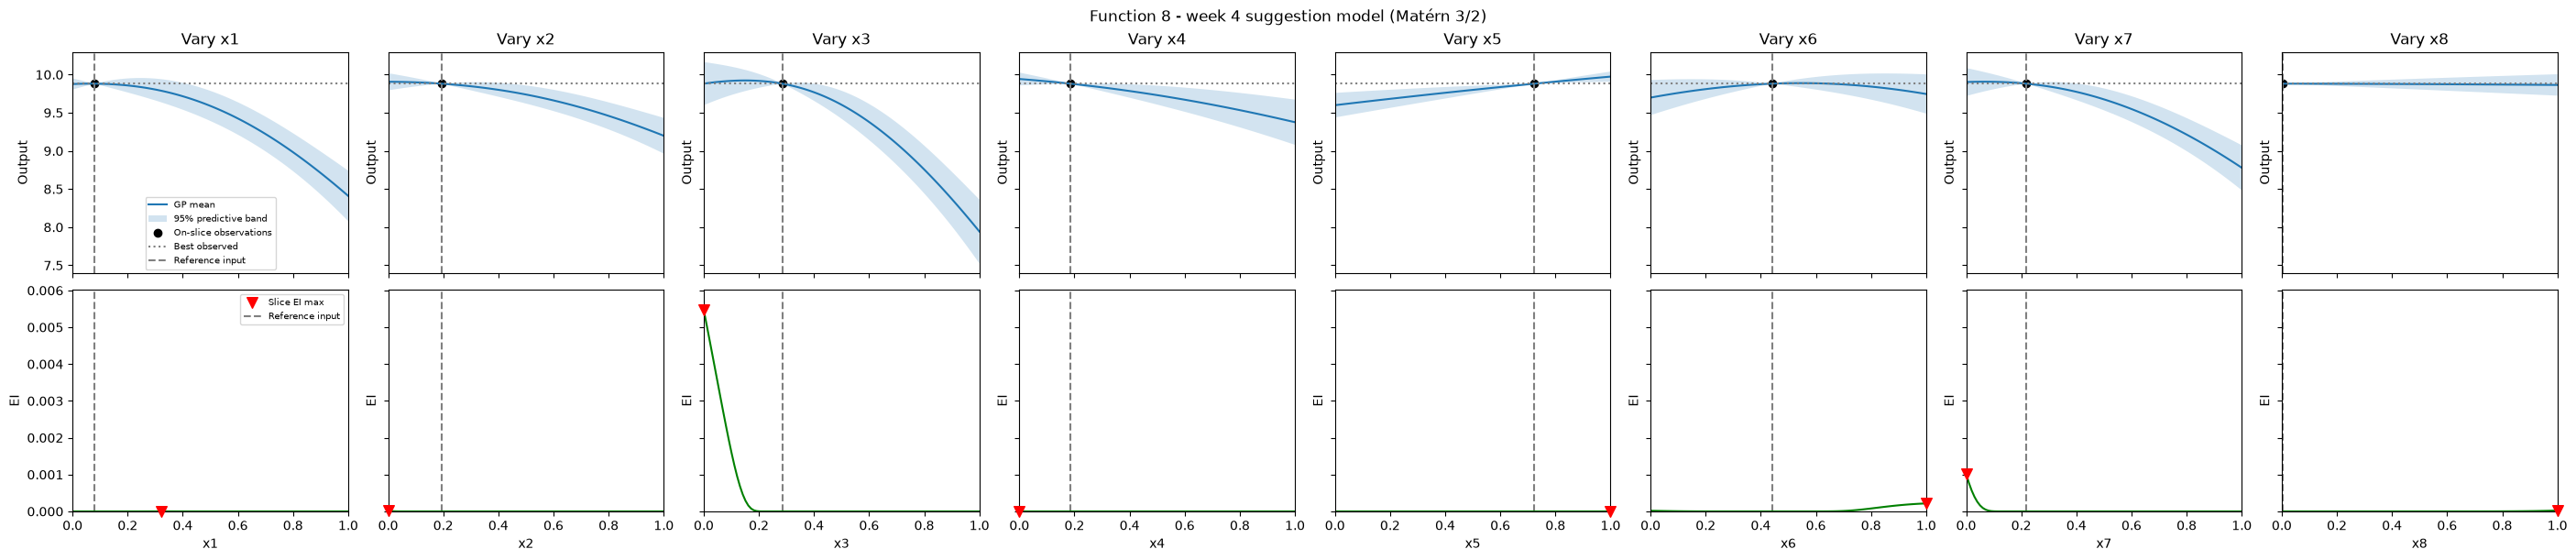

Function 8 - week 4 suggestion model kernel: 7.45**2 * Matern(length_scale=[8.94, 13.3, 6.51, 19.7, 42.9, 13.7, 9.32, 100], nu=1.5) + WhiteKernel(noise_level=1e-08)



In [6]:
plot_function_ids = (1, 2, 3, 4, 5, 6, 7, 8)
N_CANDIDATES = CONFIG["candidates"]

for function_id in plot_function_ids:
    observations = load_observations(data_root, function_id, up_to_week=WEEKS[-1])
    kernel = make_matern_32_kernel(observations.dimension, LENGTH_CAPS[function_id])
    settings = stored_predictions["acquisition_settings"][function_id - 1]
    optimizer = BayesianOptimizer(
        observations,
        OptimisationConfig(budget=1, candidates = N_CANDIDATES, kernel=kernel, xi=XI_VALUES[function_id]),
    )
    plot = plot_gp_2d if observations.dimension == 2 else plot_gp_slices
    figure, _ = plot(
        optimizer,
        n=100,
        # candidate=stored_inputs[function_id - 1],
        # expected_mean=stored_predictions["expected_outputs"][function_id - 1],
        # expected_std=stored_predictions["stds"][function_id - 1],
        # expected_ei=stored_predictions["acquisition_scores"][function_id - 1],
    )
    figure.suptitle(f"Function {function_id} - week {WEEKS[-1] + 1} suggestion model (Matérn 3/2)")
    display(figure)
    plt.close(figure)
    print(f"Function {function_id} - week {WEEKS[-1]+1} suggestion model kernel: {optimizer._model.kernel_}")
    print()

## 4. Next candidates: heuristics for F1-F2, EI for F3-F8

- **F1: `(0.550000, 0.681526)`**. Hold x2 near the isolated negative response at `(0.650114, 0.681526)` and vary x1 to test the GP's nearly flat x1 assumption. A near-zero response would challenge the broad negative band; a negative response would support its persistence on this slice. This is a learning-oriented query, not an exploitation of the negative point: the objective is maximized and nearly all other observations are effectively zero.
- **F2: `(0.702637, 0.500000)`**. Keep x1 at the best observed value to six decimals and test an intermediate x2. Responses around 0.61 and 0.60 were observed near x1 = 0.70 at widely separated x2 values, but with different x1. This query tests whether the promising region persists between them; it does not assume x2 is irrelevant.
- **F3-F8:** select the maximum EI over the optimizer's seeded 1,000,000-candidate pool, using observations through week 3, Matérn 3/2, configured length caps and the recommended `XI_VALUES` from Notebook 02 (alpha 0.1 for F1-F5; 0.2 for F6-F8). The optimizer's single-xi sweep batches predictions to bound memory and performs the same pool maximization as a suggestion; this is not a guaranteed global maximum.

The table predicts mean, standard deviation and EI at the actual chosen point, including both heuristic points. These are model predictions, not measured outcomes. Submission strings use six decimals; historical data and stored suggestions are not overwritten.

In [7]:
from bayesian_bbo.submission import format_submission

HEURISTIC_CANDIDATES = {1: (0.550000, 0.681526), 2: (0.702637, 0.500000)}
candidate_records = []
for function_id in FUNCTION_IDS:
    observations = load_observations(data_root, function_id, up_to_week=WEEKS[-1])
    kernel = make_matern_32_kernel(observations.dimension, LENGTH_CAPS[function_id])
    optimizer = BayesianOptimizer(observations, OptimisationConfig(
        budget=1, candidates=CONFIG['candidates'], kernel=kernel, xi=XI_VALUES[function_id]))
    if function_id in HEURISTIC_CANDIDATES:
        candidate = np.asarray(HEURISTIC_CANDIDATES[function_id])
        means, stds, scores = optimizer.predict(candidate[None, :])
        mean, std, score = float(means[0]), float(stds[0]), float(scores[0])
        method = 'Heuristic axis test'
    else:
        candidate, mean, std, score = optimizer.suggest_ei_sweep([XI_VALUES[function_id]])[0]
        method = 'Optimizer pool EI max'
    candidate_records.append(dict(function_id=function_id, method=method, candidate=tuple(candidate),
                                  submission=format_submission(candidate), xi=XI_VALUES[function_id],
                                  expected_mean=mean, expected_std=std, expected_ei=score))
next_candidates = pd.DataFrame(candidate_records)
display(next_candidates)

/home/pabloncho/repositories/bayesian-bbo/.venv/lib/python3.14/site-packages/sklearn/gaussian_process/kernels.py:455: ConvergenceWarning: The optimal value found for dimension 0 of parameter k1__k2__length_scale is close to the specified upper bound 31.622776601683793. Increasing the bound and calling fit again may find a better value.
  warnings.warn(
/home/pabloncho/repositories/bayesian-bbo/.venv/lib/python3.14/site-packages/sklearn/gaussian_process/kernels.py:445: ConvergenceWarning: The optimal value found for dimension 0 of parameter k2__noise_level is close to the specified lower bound 1e-08. Decreasing the bound and calling fit again may find a better value.
  warnings.warn(


/home/pabloncho/repositories/bayesian-bbo/.venv/lib/python3.14/site-packages/sklearn/gaussian_process/kernels.py:455: ConvergenceWarning: The optimal value found for dimension 1 of parameter k1__k2__length_scale is close to the specified upper bound 31.622776601683793. Increasing the bound and calling fit again may find a better value.
  warnings.warn(


/home/pabloncho/repositories/bayesian-bbo/.venv/lib/python3.14/site-packages/sklearn/gaussian_process/kernels.py:455: ConvergenceWarning: The optimal value found for dimension 0 of parameter k1__k2__length_scale is close to the specified upper bound 31.622776601683793. Increasing the bound and calling fit again may find a better value.
  warnings.warn(
/home/pabloncho/repositories/bayesian-bbo/.venv/lib/python3.14/site-packages/sklearn/gaussian_process/kernels.py:455: ConvergenceWarning: The optimal value found for dimension 1 of parameter k1__k2__length_scale is close to the specified upper bound 31.622776601683793. Increasing the bound and calling fit again may find a better value.
  warnings.warn(


/home/pabloncho/repositories/bayesian-bbo/.venv/lib/python3.14/site-packages/sklearn/gaussian_process/kernels.py:445: ConvergenceWarning: The optimal value found for dimension 0 of parameter k2__noise_level is close to the specified lower bound 1e-08. Decreasing the bound and calling fit again may find a better value.
  warnings.warn(


/home/pabloncho/repositories/bayesian-bbo/.venv/lib/python3.14/site-packages/sklearn/gaussian_process/kernels.py:455: ConvergenceWarning: The optimal value found for dimension 0 of parameter k1__k2__length_scale is close to the specified upper bound 100.0. Increasing the bound and calling fit again may find a better value.
  warnings.warn(
/home/pabloncho/repositories/bayesian-bbo/.venv/lib/python3.14/site-packages/sklearn/gaussian_process/kernels.py:445: ConvergenceWarning: The optimal value found for dimension 0 of parameter k2__noise_level is close to the specified lower bound 1e-08. Decreasing the bound and calling fit again may find a better value.
  warnings.warn(


/home/pabloncho/repositories/bayesian-bbo/.venv/lib/python3.14/site-packages/sklearn/gaussian_process/kernels.py:455: ConvergenceWarning: The optimal value found for dimension 2 of parameter k1__k2__length_scale is close to the specified upper bound 31.622776601683793. Increasing the bound and calling fit again may find a better value.
  warnings.warn(


/home/pabloncho/repositories/bayesian-bbo/.venv/lib/python3.14/site-packages/sklearn/gaussian_process/kernels.py:455: ConvergenceWarning: The optimal value found for dimension 7 of parameter k1__k2__length_scale is close to the specified upper bound 100.0. Increasing the bound and calling fit again may find a better value.
  warnings.warn(
/home/pabloncho/repositories/bayesian-bbo/.venv/lib/python3.14/site-packages/sklearn/gaussian_process/kernels.py:445: ConvergenceWarning: The optimal value found for dimension 0 of parameter k2__noise_level is close to the specified lower bound 1e-08. Decreasing the bound and calling fit again may find a better value.
  warnings.warn(


,function_id,method,candidate,submission,xi,expected_mean,expected_std,expected_ei
0,1,Heuristic axis test,"(0.55, 0.681526)",0.550000-0.681526,0.000100,-0.003606,0.000006,0.000000
1,2,Heuristic axis test,"(0.702637, 0.5)",0.702637-0.500000,0.023267,0.604945,0.033011,0.003349
2,3,Optimizer pool EI max,"(0.947062, 0.004655, 0.308533)",0.947062-0.004655-0.308533,0.008392,-0.013200,0.064582,0.018673
3,4,Optimizer pool EI max,"(0.408628, 0.415278, 0.367734, 0.42364)",0.408628-0.415278-0.367734-0.423640,0.770138,-1.054474,0.814679,0.120138
4,5,Optimizer pool EI max,"(0.521778, 0.945288, 0.998122, 0.995876)",0.521778-0.945288-0.998122-0.995876,45.216176,1608.846266,24.701896,2.016113
5,6,Optimizer pool EI max,"(0.275981, 0.014585, 0.598845, 0.989524, 0.002...",0.275981-0.014585-0.598845-0.989524-0.002492,0.100055,-0.570396,0.316614,0.049801
6,7,Optimizer pool EI max,"(0.004766, 0.024159, 0.641629, 0.165455, 0.346...",0.004766-0.024159-0.641629-0.165455-0.346867-0...,0.098860,2.223120,0.185294,0.008189
7,8,Optimizer pool EI max,"(0.031763, 0.022432, 0.081301, 0.006484, 0.954...",0.031763-0.022432-0.081301-0.006484-0.954331-0...,0.200978,10.108850,0.215298,0.099918


## 5. Submission format and save week 4 predictions

Display the final F1-F8 selections in six-decimal submission format and save `weekly_updates/week_4/inputs.json` and `predictions.json` using the same schema as week-2 Notebook 06, sections 9-10. Predictions include means, standard deviations, expected best-so-far (incumbent plus EI with xi = 0), configured EI scores and acquisition settings. For F1-F2, the score is EI at the heuristic point, not maximum EI. Different existing exports are protected from overwrite.

In [8]:
from bayesian_bbo.data import save_predictions

export_rows = next_candidates.sort_values('function_id').reset_index(drop=True)
if export_rows.function_id.tolist() != list(FUNCTION_IDS):
    raise ValueError('Export requires exactly one candidate per function in FUNCTION_IDS order.')
submission_points = export_rows[['function_id', 'submission']]
with pd.option_context('display.max_colwidth', None):
    display(submission_points)
suggested_points = [[float(value) for value in text.split('-')] for text in export_rows.submission]
if suggested_points != [list(point) for point in export_rows.candidate]:
    raise ValueError('Exported coordinates differ from the points used for predictions.')
best_outputs = [load_observations(data_root, function_id, up_to_week=WEEKS[-1]).best_output
                for function_id in FUNCTION_IDS]
week_directory = data_root / 'weekly_updates' / f'week_{WEEKS[-1] + 1}'
saved_prediction_paths = save_predictions(
    export_rows.expected_mean.tolist(), suggested_points, export_rows.expected_std.tolist(),
    best_outputs, week_directory,
    acquisition_scores=export_rows.expected_ei.tolist(),
    acquisition_settings=[dict(name='ei', xi=float(xi), best=float(best))
                          for xi, best in zip(export_rows.xi, best_outputs)],
)
saved_prediction_paths

,function_id,submission
0,1,0.550000-0.681526
1,2,0.702637-0.500000
2,3,0.947062-0.004655-0.308533
3,4,0.408628-0.415278-0.367734-0.423640
4,5,0.521778-0.945288-0.998122-0.995876
5,6,0.275981-0.014585-0.598845-0.989524-0.002492
6,7,0.004766-0.024159-0.641629-0.165455-0.346867-0.663761
7,8,0.031763-0.022432-0.081301-0.006484-0.954331-0.165175-0.027619-0.074118


Saved and verified /home/pabloncho/repositories/bayesian-bbo/data/weekly_updates/week_4/inputs.json
Saved and verified /home/pabloncho/repositories/bayesian-bbo/data/weekly_updates/week_4/predictions.json


{'inputs.json': PosixPath('/home/pabloncho/repositories/bayesian-bbo/data/weekly_updates/week_4/inputs.json'),
 'predictions.json': PosixPath('/home/pabloncho/repositories/bayesian-bbo/data/weekly_updates/week_4/predictions.json')}